# Tasks 2, 3 and 4 Model and SHAP Explanations

Train and evaluate the Task 2 Random Forest, explain the Task 3 false negative, and examine global held-out patterns in Task 4. Run all cells from top to bottom. All Task 4 code is included directly below; no separate Task 4 Python helper is required.


## 1 Imports and dataset preview

Load the original stroke dataset using `DataLoader` from the adapted supplied `utils.py`. Restart the kernel after changing the helper, then run all cells from top to bottom.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

SEED = 2021
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT = next(
    (folder for folder in candidates
     if (folder / "data/healthcare-dataset-stroke-data.csv").exists()),
    None,
)
if PROJECT is None:
    raise FileNotFoundError("Download the dataset into data/ and run from the submission folder.")

sys.path.insert(0, str(PROJECT))
from utils import DataLoader

data_loader = DataLoader()
data_loader.load_dataset(PROJECT / "data/healthcare-dataset-stroke-data.csv")
data = data_loader.data
print("Python:", sys.version.split()[0])
print("SHAP:", shap.__version__)
print("Dataset shape:", data.shape)
display(data.head())


Python: 3.9.6
SHAP: 0.49.1
Dataset shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 2 Training and test split

Call `data_loader.get_data_split()` with stratification and seed 2021. The helper excludes the identifier and target before splitting; it does not fit any preprocessing here.


In [2]:
X_train, X_test, y_train, y_test = data_loader.get_data_split(
    test_size=0.20, random_state=SEED, stratify=True,
)

split_counts = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Test": y_test.value_counts(),
}).reindex([0, 1])
split_counts.index.name = "stroke"
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
display(split_counts)


Training rows: 4088
Test rows: 1022


,Training,Test
stroke,,
0,3889,972
1,199,50


## 3 Preprocess the features

Call `data_loader.preprocess_split()` to fit the BMI median and indicator columns on training records, then align the test inputs. The median, 21-feature order and calculations are unchanged. The helper's original `preprocess_data()` zero-filling method is retained only for the Task 1 demonstration and is not called here.


In [3]:
X_train, X_test = data_loader.preprocess_split(X_train, X_test)
bmi_median = data_loader.bmi_median

print("Training BMI median:", bmi_median)
print("Encoded training shape:", X_train.shape)
print("Encoded test shape:", X_test.shape)
print("Missing values in training:", X_train.isna().sum().sum())
print("Missing values in test:", X_test.isna().sum().sum())


Training BMI median: 28.1
Encoded training shape: (4088, 21)
Encoded test shape: (1022, 21)
Missing values in training: 0
Missing values in test: 0


## 4 Oversample the training set

Call `data_loader.oversample()` with seed 2021 to duplicate stroke training records. The test set is unchanged.


In [4]:
X_train_balanced, y_train_balanced = data_loader.oversample(
    X_train, y_train, random_state=SEED,
)
sampler = data_loader.sampler

balance_counts = pd.DataFrame({
    "Before oversampling": y_train.value_counts(),
    "After oversampling": y_train_balanced.value_counts(),
}).reindex([0, 1])
balance_counts.index.name = "stroke"
display(balance_counts)
print("Balanced training shape:", X_train_balanced.shape)
print("Unchanged test shape:", X_test.shape)


/Users/benjy/UM/XAI/.venv/lib/python3.9/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/Users/benjy/UM/XAI/.venv/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(
Balanced training shape: (7778, 21)
Unchanged test shape: (1022, 21)


,Before oversampling,After oversampling
stroke,,
0,3889,3889
1,199,3889


## 5 Train the Random Forest

Fit 100 trees using the balanced training data and a fixed random seed.


In [5]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=SEED,
    n_jobs=-1,
)
rf.fit(X_train_balanced, y_train_balanced)
y_pred = rf.predict(X_test)
print("Random Forest training finished.")


Random Forest training finished.


## 6 Evaluate the model

Report accuracy, macro F1, class-level metrics and a confusion matrix. Compare with always predicting no stroke.


In [6]:
majority_pred = np.zeros(len(y_test), dtype=int)
evaluation = pd.DataFrame({
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, majority_pred),
    ],
    "Macro F1": [
        f1_score(y_test, y_pred, average="macro"),
        f1_score(y_test, majority_pred, average="macro", zero_division=0),
    ],
}, index=["Random Forest", "Always predict no stroke"])
display(evaluation.round(4))

print("Classification report:")
print(classification_report(
    y_test, y_pred, labels=[0, 1],
    target_names=["No stroke", "Stroke"], zero_division=0,
))
confusion = pd.DataFrame(
    confusion_matrix(y_test, y_pred, labels=[0, 1]),
    index=["Actual no stroke", "Actual stroke"],
    columns=["Predicted no stroke", "Predicted stroke"],
)
display(confusion)


Classification report:
              precision    recall  f1-score   support

   No stroke       0.95      0.99      0.97       972
      Stroke       0.20      0.06      0.09        50

    accuracy                           0.94      1022
   macro avg       0.58      0.52      0.53      1022
weighted avg       0.92      0.94      0.93      1022



,Accuracy,Macro F1
Random Forest,0.9423,0.5312
Always predict no stroke,0.9511,0.4875


,Predicted no stroke,Predicted stroke
Actual no stroke,960,12
Actual stroke,47,3


Accuracy is **94.23%**, but only **3 of 50 stroke cases** are detected (6% recall). High overall accuracy therefore hides poor stroke detection.


## 7 Create the SHAP explainer

Tree SHAP suits the Random Forest's tree structure. Explain all test patients and select the stroke class (`1`). Positive contributions raise the predicted stroke probability relative to the baseline; negative contributions lower it.


In [7]:
explainer = shap.TreeExplainer(rf)
shap_values = explainer(X_test)

stroke_class_index = list(rf.classes_).index(1)
stroke_shap = shap_values[:, :, stroke_class_index]

print("Model classes:", rf.classes_)
print("All-class SHAP shape:", shap_values.values.shape)
print("Test data shape:", X_test.shape)
print("Stroke SHAP shape:", stroke_shap.values.shape)


Model classes: [0 1]
All-class SHAP shape: (1022, 21, 2)
Test data shape: (1022, 21)
Stroke SHAP shape: (1022, 21)


## 8 Verify the SHAP explanations

Check that **baseline + sum of contributions = predicted stroke probability** for every test patient, then inspect one patient.


In [8]:
stroke_probabilities = rf.predict_proba(X_test)[:, stroke_class_index]
reconstructed = stroke_shap.base_values + stroke_shap.values.sum(axis=1)
shap_matches = np.allclose(reconstructed, stroke_probabilities, atol=1e-6)

print("SHAP matches model probabilities:", shap_matches)
print("Maximum absolute reconstruction error:",
    np.max(np.abs(reconstructed - stroke_probabilities)))

patient_index = 0
patient_summary = pd.Series({
    "Original dataset index": X_test.index[patient_index],
    "Actual label": y_test.iloc[patient_index],
    "Predicted label": y_pred[patient_index],
    "Stroke probability": stroke_probabilities[patient_index],
    "SHAP baseline": stroke_shap.base_values[patient_index],
    "Sum of contributions": stroke_shap.values[patient_index].sum(),
    "Reconstructed probability": reconstructed[patient_index],
}, name="First test patient")
display(patient_summary.to_frame())


SHAP matches model probabilities: True
Maximum absolute reconstruction error: 3.219646771412954e-15


,First test patient
Original dataset index,4926.000000
Actual label,0.000000
Predicted label,0.000000
Stroke probability,0.010000
SHAP baseline,0.500476
Sum of contributions,-0.490476
Reconstructed probability,0.010000


## Task 2 complete

The model is trained and evaluated, Tree SHAP explanations are created, and the reconstruction check passes. Continue below for Task 3 using the same fitted model, test set and explanation arrays.


# Task 3 Local SHAP Force Plot

This section explains the first false negative in the fixed held-out test-set order. It reuses the fitted Random Forest and stroke-class Tree SHAP explanations from Task 2. The selected record is dataset row 173 at test position 32, matching the Task 3 reference report. The force plot and supporting tables are exported to `output/task3/`.

In [9]:
import matplotlib.pyplot as plt


## 1 Select a held-out case

The model misses 47 of the 50 recorded stroke cases. A false negative is selected to examine one of these errors. The selection rule is the **first false negative in test-set order**, using the existing stratified split and random seed 2021. Cases are not ranked by probability or by the appearance of their explanations. This is an illustrative error analysis, not a representative sample of all missed cases.

The catalogue below identifies each prediction as a true positive, false negative, false positive or true negative.

In [10]:
case_types = np.select(
    [
        (y_test.to_numpy() == 1) & (y_pred == 1),
        (y_test.to_numpy() == 1) & (y_pred == 0),
        (y_test.to_numpy() == 0) & (y_pred == 1),
    ],
    ["True positive", "False negative", "False positive"],
    default="True negative",
)
case_catalogue = pd.DataFrame({
    "Test position": np.arange(len(X_test)),
    "Dataset row index": X_test.index,
    "Actual label": y_test.to_numpy(),
    "Predicted label": y_pred,
    "Stroke probability": stroke_probabilities,
    "Case type": case_types,
})
display(case_catalogue.groupby("Case type", sort=False).size().rename("Count").to_frame())

,Count
Case type,
True negative,960
False negative,47
False positive,12
True positive,3


In [11]:
CASE_TYPE = "False negative"
candidates = case_catalogue.loc[case_catalogue["Case type"] == CASE_TYPE]
if candidates.empty:
    raise ValueError("There are no false negatives to explain for this fitted model.")
selected_position = int(candidates.iloc[0]["Test position"])
display(case_catalogue.iloc[[selected_position]])

,Test position,Dataset row index,Actual label,Predicted label,Stroke probability,Case type
32,32,173,1,0,0.23,False negative


The selected case has actual label **1** and predicted label **0**. Its stroke-class probability is **0.23**, below the default class-1 decision threshold. With class order `[0, 1]`, a probability strictly above 0.5 produces class 1 and a tie produces class 0. The record is therefore a **false negative**.

In [12]:
assert selected_position == 32, "Selected case differs from the reference report."
assert int(X_test.index[selected_position]) == 173
assert int(y_test.iloc[selected_position]) == 1
assert int(y_pred[selected_position]) == 0
assert np.isclose(stroke_probabilities[selected_position], 0.23, rtol=0, atol=1e-12)
print("Verified reference case: test position 32, dataset row 173, false negative.")

Verified reference case: test position 32, dataset row 173, false negative.


## 2 Inspect the prediction and contributions

Tree SHAP explains the model probability for **stroke = 1**, using the same 21 encoded predictors as the forest. Values are in probability units, so a contribution of +0.05 corresponds to five percentage points in the additive reconstruction. Features are ranked by absolute contribution, while their signs are retained.

The original record is also displayed to distinguish observed values from imputed inputs.

In [13]:
i = selected_position
local_explanation = stroke_shap[i]
base_value = float(local_explanation.base_values)
contributions = pd.DataFrame({
    "Feature": X_test.columns,
    "Patient value": X_test.iloc[i].to_numpy(),
    "SHAP value": local_explanation.values,
})
contributions["Direction"] = np.select(
    [contributions["SHAP value"] > 0, contributions["SHAP value"] < 0],
    ["Increases stroke output", "Decreases stroke output"],
    default="No contribution",
)
contributions = contributions.iloc[
    np.argsort(-np.abs(contributions["SHAP value"].to_numpy()), kind="stable")
].reset_index(drop=True)
prediction_summary = case_catalogue.iloc[i].to_dict()
prediction_summary.update({
    "SHAP baseline": base_value,
    "Sum of SHAP contributions": float(local_explanation.values.sum()),
    "Reconstructed probability": float(reconstructed[i]),
    "Absolute residual": float(abs(reconstructed[i] - stroke_probabilities[i])),
})
display(pd.Series(prediction_summary, name="Selected case").to_frame())
display(contributions)

# Inspect original recorded values too: model input BMI may have been imputed.
original_record = data.loc[X_test.index[i]].drop(labels=["id"])
display(original_record.rename("Original recorded value").to_frame())
print("Original BMI missing:", bool(pd.isna(original_record["bmi"])))

assert np.isclose(reconstructed[i], stroke_probabilities[i], rtol=0, atol=1e-10)
report_contributions = contributions.head(4).copy()
remaining_sum = float(contributions.iloc[4:]["SHAP value"].sum())
report_contributions.loc[len(report_contributions)] = {
    "Feature": "Remaining 17 features combined",
    "Patient value": np.nan,
    "SHAP value": remaining_sum,
    "Direction": "Net decrease" if remaining_sum < 0 else "Net increase",
}
print("Report contribution table (probability units):")
display(report_contributions.round(6))

Original BMI missing: False
Report contribution table (probability units):


,Selected case
Test position,32
Dataset row index,173
Actual label,1
Predicted label,0
Stroke probability,0.23
Case type,False negative
SHAP baseline,0.500476
Sum of SHAP contributions,-0.270476
Reconstructed probability,0.23
Absolute residual,0.0


,Feature,Patient value,SHAP value,Direction
0,avg_glucose_level,91.02,-0.167119,Decreases stroke output
1,bmi,32.90,-0.126470,Decreases stroke output
2,hypertension,1.00,0.080174,Increases stroke output
3,age,80.00,0.044225,Increases stroke output
4,Residence_type_Rural,1.00,-0.022159,Decreases stroke output
5,smoking_status_never smoked,0.00,-0.020960,Decreases stroke output
6,Residence_type_Urban,0.00,-0.016998,Decreases stroke output
7,smoking_status_formerly smoked,1.00,-0.010300,Decreases stroke output
8,heart_disease,0.00,-0.008596,Decreases stroke output
9,gender_Male,0.00,-0.008166,Decreases stroke output


,Original recorded value
gender,Female
age,80.0
hypertension,1
heart_disease,0
ever_married,Yes
work_type,Self-employed
Residence_type,Rural
avg_glucose_level,91.02
bmi,32.9
smoking_status,formerly smoked


,Feature,Patient value,SHAP value,Direction
0,avg_glucose_level,91.02,-0.167119,Decreases stroke output
1,bmi,32.90,-0.126470,Decreases stroke output
2,hypertension,1.00,0.080174,Increases stroke output
3,age,80.00,0.044225,Increases stroke output
4,Remaining 17 features combined,NaN,-0.101286,Net decrease


## 3 Generate and export the force plot

Red contributions raise the stroke output relative to the baseline and blue contributions lower it. The plot shows the movement from approximately **0.50048** to **0.23**. Shortened labels improve readability in the static image; the interactive HTML and CSV retain the original encoded feature names. Small contributions remain included in the calculation even when their labels are hidden.

Saved plot, interactive HTML and evidence tables to: /Users/benjy/UM/XAI/Assignment1/new_submission_benjy/output/task3
Case filename prefix: case_testpos_32


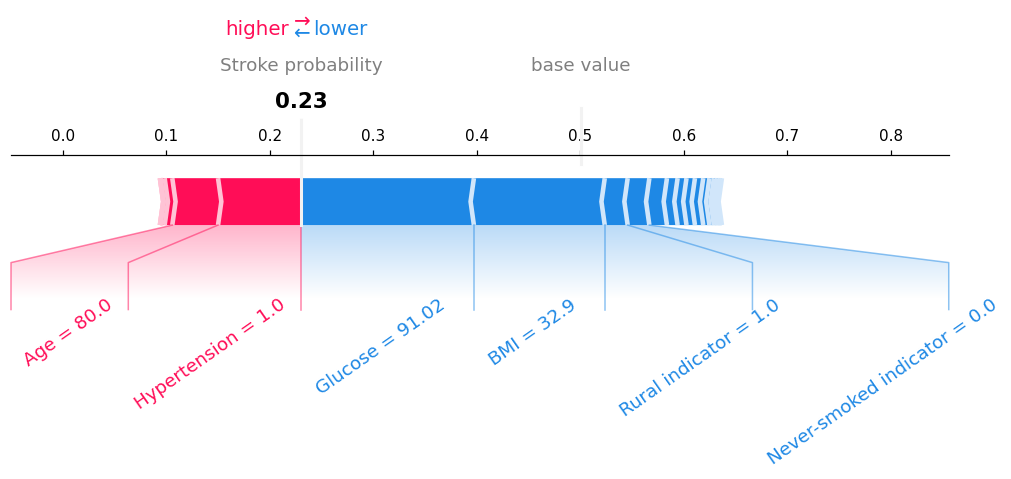

In [14]:
output_dir = PROJECT / "output" / "task3"
output_dir.mkdir(parents=True, exist_ok=True)
case_stem = f"case_testpos_{selected_position}"

plot_labels = [
    {
        "age": "Age", "hypertension": "Hypertension",
        "avg_glucose_level": "Glucose", "bmi": "BMI",
        "Residence_type_Rural": "Rural indicator",
        "smoking_status_never smoked": "Never-smoked indicator",
    }.get(name, name) for name in X_test.columns
]

shap.force_plot(
    base_value,
    local_explanation.values,
    X_test.iloc[selected_position].to_numpy(),
    feature_names=plot_labels,
    out_names="Stroke probability",
    link="identity",
    matplotlib=True,
    show=False,
    figsize=(11, 3.6),
    text_rotation=35,
    contribution_threshold=0.06,
)
plt.savefig(output_dir / f"{case_stem}_force.png", dpi=250, bbox_inches="tight")
plt.show()
plt.close()

interactive_plot = shap.force_plot(
    base_value,
    local_explanation.values,
    X_test.iloc[selected_position],
    feature_names=X_test.columns.tolist(),
    out_names="Stroke probability",
    link="identity",
)
shap.save_html(str(output_dir / f"{case_stem}_force.html"), interactive_plot)
contributions.to_csv(output_dir / f"{case_stem}_contributions.csv", index=False)
pd.Series(prediction_summary).to_frame("Value").to_csv(
    output_dir / f"{case_stem}_prediction.csv"
)
print("Saved plot, interactive HTML and evidence tables to:", output_dir)
print("Case filename prefix:", case_stem)
report_contributions.to_csv(output_dir / f"{case_stem}_report_contributions.csv", index=False)
original_record.to_frame("Original recorded value").to_csv(
    output_dir / f"{case_stem}_original_record.csv"
)

## 4 Interpretation of the selected prediction

The selected record is an 80-year-old female with hypertension, no recorded heart disease, average glucose **91.02**, BMI **32.9**, and formerly smoked status. BMI is observed, so the training-median replacement is not used for this record. No predictor is missing in the original record.

The baseline stroke-class probability is **0.5004757007**. The 21 contributions sum to **−0.2704757007**, reducing the output by approximately **27.05 percentage points** to **0.23**:

`0.5004757007 − 0.2704757007 = 0.2300000000`

Using full precision, the absolute reconstruction residual is approximately **5.27 × 10⁻¹⁶**. The explanation therefore reconstructs this model prediction numerically. The baseline comes from training-path statistics in the forest fitted on oversampled data; it is not the original dataset stroke prevalence.

The largest downward contributions are **average glucose = 91.02** (−0.167119, approximately −16.71 percentage points) and **BMI = 32.9** (−0.126470, approximately −12.65 points). The largest upward contributions are **hypertension = 1** (+0.080174, approximately +8.02 points) and **age = 80** (+0.044225, approximately +4.42 points). The remaining 17 encoded features have a combined signed contribution of **−0.101286**. These downward contributions outweigh the upward contributions and leave the prediction below the classification threshold.

Age and hypertension push this model output upward. The negative contribution for BMI does not establish that this BMI is protective: the values describe this fitted model relative to its reference distribution, including interactions with other inputs. They are not causal effects or predictions of what would happen if a measurement were changed. An encoded indicator equal to zero can also contribute; for example, `smoking_status_never smoked = 0` means absence of that category, not absence of smoking history.

The model predicts no stroke despite the recorded stroke label. This case makes one missed classification inspectable and illustrates the model's low stroke recall. Numerical agreement between SHAP and the model does not establish predictive usefulness. The uncalibrated score does not establish future stroke risk or provide a diagnosis.

**Figure caption:** Local Tree SHAP force plot for the Random Forest prediction for held-out dataset row 173 (actual class 1; predicted class 0). The horizontal axis is stroke-class probability. Red contributions push the output higher and blue contributions push it lower, producing 0.23 from a baseline of approximately 0.50048. Static plot labels are shortened; the exported contribution tables retain exact model-input names.

## Task 3 complete

The selected prediction, complete contributions, compact report table, original recorded values, static force plot and interactive HTML are saved under `output/task3/`, with filename prefix `case_testpos_32`. Task 4's global explanation is outside this notebook.

# Task 4 Global SHAP Summary Plot

Reuse the same fitted model, test records and stroke-class explanations. No additional model fitting or test sampling is performed.

## 5.1 Population and plotting settings

The Task 2 Random Forest (100 trees, random seed 2021) was explained for all 1,022 held-out test records: 972 no-stroke records and 50 stroke records (4.89%). The original stratified 80:20 split was retained. No test records were resampled or selected according to their predictions. Training-only BMI median imputation and one-hot encoding produced the same 21 predictors used by the fitted model.

SHAP 0.49.1 TreeExplainer used tree_path_dependent attribution with no explicit background sample. Its reference distribution is represented by training path counts stored in the forest fitted to 7,778 oversampled training records. The baseline was 0.500476; it is not the observed stroke prevalence. Although the explainer setting is model_output='raw', reconstruction confirms that this forest's selected class output is P(stroke = 1), at class index 1. The maximum absolute reconstruction error across the test set was 3.22 × 10⁻¹⁵.

Figure 3 displays the ten highest-ranked encoded predictors. All 21 appear in the separate full plot and importance CSV. Categories remain individual 0/1 indicators; no categorical aggregation was applied. Ranking uses mean absolute SHAP across every test record [1]. Seed 2021 fixes the dot arrangement. Positive SHAP values raise the stroke-class output relative to the baseline; negative values lower it. A contribution of 0.01 corresponds to one percentage point in the reconstruction.

In [15]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

LABELS = {
    'age': 'Age', 'hypertension': 'Hypertension (1 = yes)',
    'heart_disease': 'Heart disease (1 = yes)',
    'avg_glucose_level': 'Average glucose', 'bmi': 'BMI',
}

def label(name):
    if name in LABELS:
        return LABELS[name]
    for prefix, title in [('gender_', 'Gender'), ('ever_married_', 'Ever married'),
                          ('work_type_', 'Work'), ('Residence_type_', 'Residence'),
                          ('smoking_status_', 'Smoking')]:
        if name.startswith(prefix):
            return title + ': ' + name[len(prefix):].replace('_', ' ') + ' (0/1)'
    return name

def export_task4(X_test, y_test, stroke_shap, probabilities, out, seed=2021):
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    values = np.asarray(stroke_shap.values, dtype=float)
    base = np.broadcast_to(np.asarray(stroke_shap.base_values), (len(X_test),))
    probabilities = np.asarray(probabilities)
    assert values.shape == X_test.shape == (1022, 21)
    assert list(stroke_shap.feature_names) == list(X_test.columns)
    assert np.isfinite(values).all() and np.isfinite(X_test.to_numpy()).all()
    assert np.array_equal(X_test.index, y_test.index)
    residual = float(np.max(np.abs(base + values.sum(axis=1) - probabilities)))
    assert residual < 1e-10
    importance = pd.DataFrame({
        'feature': X_test.columns,
        'mean_absolute_shap': np.abs(values).mean(axis=0),
        'mean_signed_shap': values.mean(axis=0),
        'positive_contributions': (values > 0).sum(axis=0),
        'negative_contributions': (values < 0).sum(axis=0),
    }).sort_values('mean_absolute_shap', ascending=False, kind='stable').reset_index(drop=True)
    importance.insert(0, 'rank', np.arange(1, len(importance) + 1))
    importance.to_csv(out / 'global_importance.csv', index=False)
    # Descriptive checks for direction: compare low/high observed value groups.
    patterns = []
    for name in X_test.columns:
        j = X_test.columns.get_loc(name)
        x = X_test[name]
        binary = set(x.unique()).issubset({0, 1})
        lo = x == 0 if binary else x <= x.quantile(.25)
        hi = x == 1 if binary else x >= x.quantile(.75)
        for group, mask in [('low_or_absent', lo), ('high_or_present', hi)]:
            v = values[mask.to_numpy(), j]
            patterns.append({'feature': name, 'group': group, 'n': len(v),
                             'value_min': float(x[mask].min()) if len(v) else None,
                             'value_max': float(x[mask].max()) if len(v) else None,
                             'mean_shap': float(v.mean()) if len(v) else None,
                             'positive_fraction': float((v > 0).mean()) if len(v) else None})
    pd.DataFrame(patterns).to_csv(out / 'feature_value_patterns.csv', index=False)
    plot_explanation = shap.Explanation(values=values, base_values=base,
        data=X_test.to_numpy(), feature_names=[label(c) for c in X_test.columns])
    for count, stem, height in [(10, 'global_beeswarm_top10', 6.2),
                                 (21, 'global_beeswarm_all21', 10.2)]:
        np.random.seed(seed)  # Reproducible dot arrangement, not test sampling.
        shap.plots.beeswarm(plot_explanation, max_display=count,
            group_remaining_features=False, plot_size=(11.2, height), show=False)
        plt.xlabel('SHAP value for stroke = 1 (probability units)')
        plt.title('Random Forest: held-out stroke-class explanations\n'
                  '1,022 records | 50 stroke records | ranked by mean absolute SHAP',
                  fontsize=12, pad=18)
        plt.savefig(out / (stem + '.png'), dpi=240, bbox_inches='tight', facecolor='white')
        plt.close()
    fig, ax = plt.subplots(figsize=(9, 5))
    top = importance.head(10).iloc[::-1]
    ax.barh([label(f) for f in top.feature], top.mean_absolute_shap, color='#26728e')
    ax.set_xlabel('Mean absolute SHAP (probability units)')
    ax.set_title('Global contribution magnitude across all 1,022 test records')
    fig.tight_layout()
    fig.savefig(out / 'global_importance_top10.png', dpi=240, bbox_inches='tight')
    plt.close(fig)
    pos = int(np.flatnonzero(X_test.index.to_numpy() == 173)[0])
    local = pd.DataFrame({'feature': X_test.columns,
        'patient_value': X_test.iloc[pos].to_numpy(), 'local_shap': values[pos]})
    local = importance[['rank', 'feature', 'mean_absolute_shap']].merge(local, on='feature')
    local.to_csv(out / 'local_global_comparison.csv', index=False)
    metadata = dict(model='RandomForestClassifier, 100 trees, seed 2021',
        explainer='TreeExplainer', feature_perturbation='tree_path_dependent',
        background='Implicit training path counts in the fitted forest; no explicit background sample',
        model_output_setting='raw', verified_output='P(stroke = 1)', class_index=1,
        n_test=len(X_test), n_positive=int(y_test.sum()), n_features=X_test.shape[1],
        displayed_features=10, full_plot_features=21, categorical_grouping=False,
        sample_rule='All held-out test records, in original test order; no subsampling',
        seed=seed, base_value=float(base[0]), maximum_reconstruction_error=residual,
        local_case=dict(dataset_index=173, test_position=pos, actual=int(y_test.iloc[pos]),
            probability=float(probabilities[pos]), contribution_sum=float(values[pos].sum())),
        test_index_sha256=hashlib.sha256(X_test.index.to_numpy(dtype=np.int64).tobytes()).hexdigest(),
        shap_version=shap.__version__, python=platform.python_version())
    (out / 'task4_verification.json').write_text(json.dumps(metadata, indent=2) + '\n')
    print(importance.head(10).to_string(index=False))
    print(json.dumps(metadata, indent=2))
    return importance, metadata


 rank                        feature  mean_absolute_shap  mean_signed_shap  positive_contributions  negative_contributions
    1                            age            0.165485         -0.146701                     136                     886
    2              avg_glucose_level            0.092208         -0.091795                       9                    1013
    3                            bmi            0.081577         -0.081216                      11                    1011
    4                   hypertension            0.021102         -0.012561                      87                     935
    5                  heart_disease            0.013833         -0.009769                      50                     972
    6               ever_married_Yes            0.013531         -0.006066                     579                     443
    7    smoking_status_never smoked            0.010791         -0.009195                     139                     883
    8           

,rank,feature,mean_absolute_shap,mean_signed_shap,positive_contributions,negative_contributions
0,1,age,0.165485,-0.146701,136,886
1,2,avg_glucose_level,0.092208,-0.091795,9,1013
2,3,bmi,0.081577,-0.081216,11,1011
3,4,hypertension,0.021102,-0.012561,87,935
4,5,heart_disease,0.013833,-0.009769,50,972


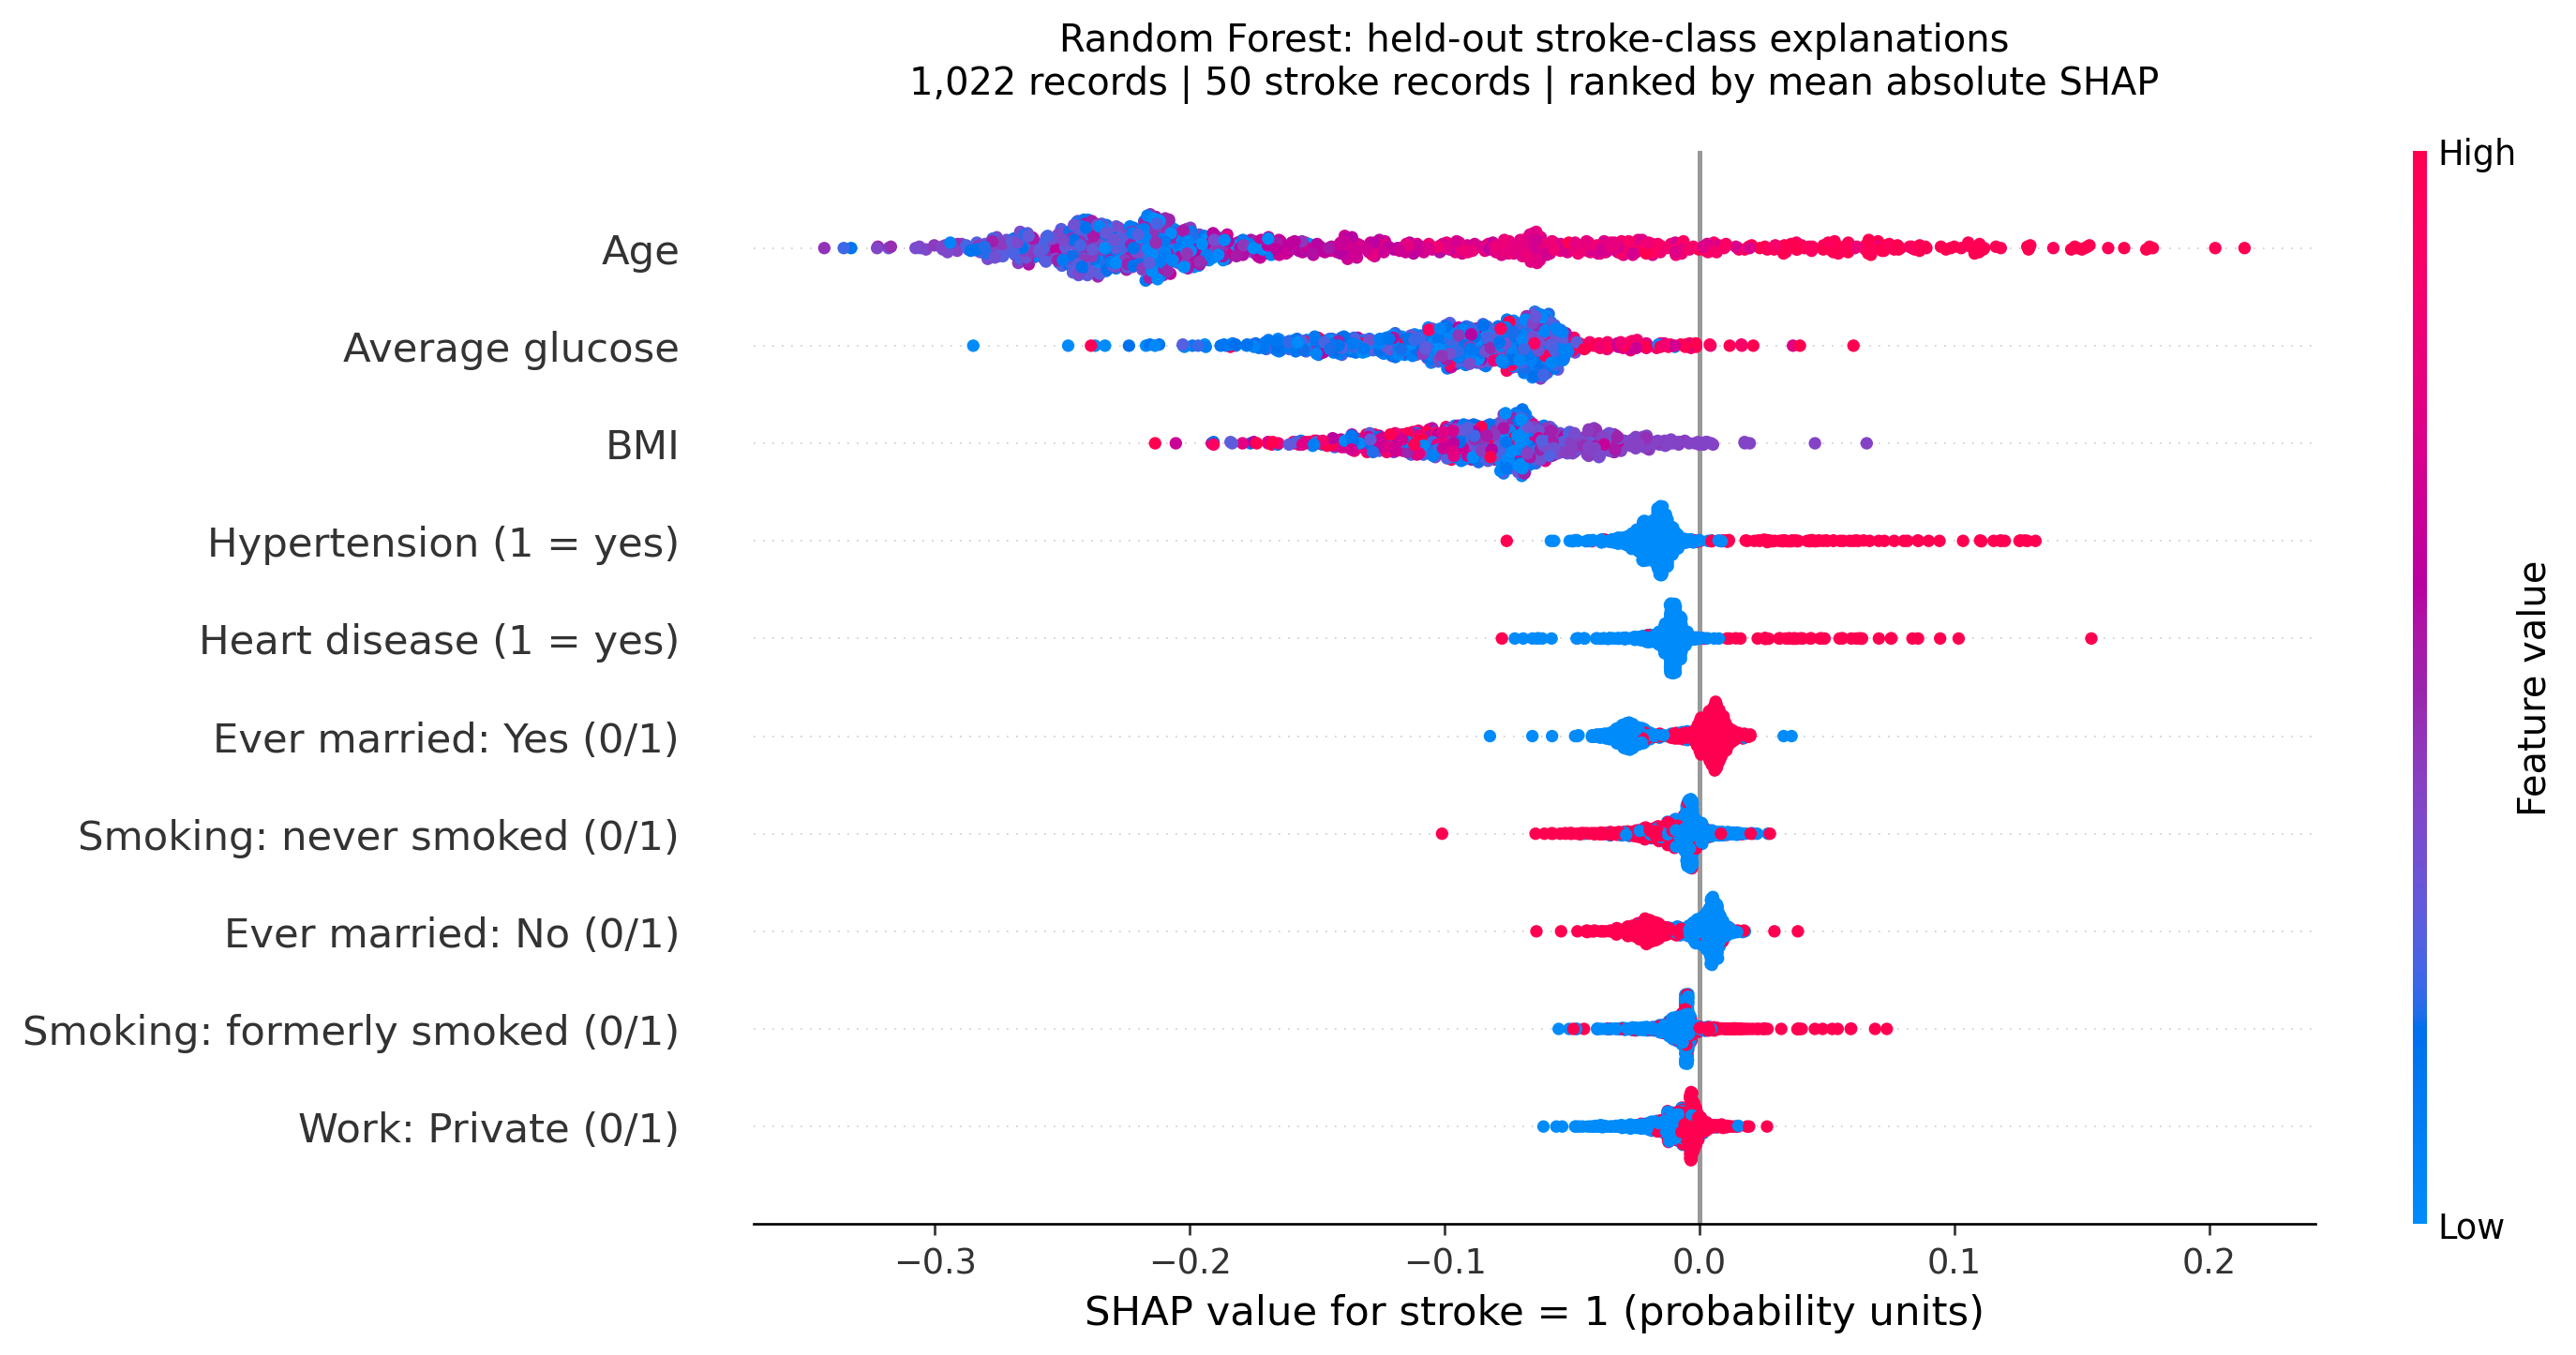

In [16]:
task4_dir = PROJECT / "output" / "task4"
global_importance, task4_checks = export_task4(
    X_test, y_test, stroke_shap, stroke_probabilities, task4_dir, seed=SEED
)
assert shap_matches and task4_checks["maximum_reconstruction_error"] < 1e-10
display(global_importance.head(5))
from IPython.display import Image
display(Image(filename=str(task4_dir / "global_beeswarm_top10.png")))


Figure 3. Global SHAP beeswarm for the Task 2 Random Forest, explaining stroke = 1 across all 1,022 held-out records. Each dot is one record for one feature. Horizontal position is the signed contribution in probability units; red indicates higher feature values and blue lower values. For binary indicators, high means 1 and low means 0. Rows are ordered by mean absolute contribution. The top ten of 21 encoded predictors are shown, without combining the remaining features.

## 5.2 Global importance and patterns

Age is the most influential encoded predictor (mean absolute SHAP 0.165485), followed by glucose (0.092208) and BMI (0.081577). These magnitudes describe average absolute contributions, not error rates, causal effects or percentage shares. Hypertension and heart disease rank fourth and fifth. Their lower average magnitude does not prevent a large contribution for a particular patient.

Age shows the clearest directional gradient: younger records cluster on the negative side, while older records extend towards positive contributions. All 260 records aged 25 or younger have negative age contributions (mean −0.226953). Among 260 records aged 61 or older, the mean is +0.008034, but only 49.23% have positive contributions. Thus, older age is not an upward contribution for every patient.

Glucose is negative for 1,013 of 1,022 records. Higher glucose values tend to extend further right, but this is usually a less negative contribution rather than a positive one. The lowest glucose quartile has mean SHAP −0.095934 and the highest quartile −0.069831. These overlapping patterns do not establish a monotonic effect.

BMI contributions are also predominantly negative (1,011 records), with a mixed pattern across values. Every record in the highest BMI quartile (BMI ≥32.9; n = 256) has a negative contribution, averaging −0.107065. The lowest quartile averages −0.088004. The plot therefore does not support a simple claim that higher BMI increases this model's output. Some near-middle values contribute positively; missing BMI was replaced with 28.1, which may affect the pattern.

Hypertension and heart disease indicators are generally positive when present and slightly negative when absent. Positive contributions occur in 83 of 100 records with hypertension and 44 of 52 with heart disease. Exceptions show that the direction also depends on the other recorded features. The colour scale represents presence or absence for indicators, not clinical severity.

In [17]:
display(pd.read_csv(task4_dir / "feature_value_patterns.csv").head(10))
local_global = pd.read_csv(task4_dir / "local_global_comparison.csv")
display(local_global.head(5))
assert task4_checks["local_case"]["dataset_index"] == int(X_test.index[selected_position])
assert np.isclose(task4_checks["local_case"]["probability"], 0.23)


,feature,group,n,value_min,value_max,mean_shap,positive_fraction
0,age,low_or_absent,260,0.16,25.00,-0.226953,0.000000
1,age,high_or_present,260,61.00,82.00,0.008034,0.492308
2,hypertension,low_or_absent,922,0.00,0.00,-0.018240,0.004338
3,hypertension,high_or_present,100,1.00,1.00,0.039802,0.830000
4,heart_disease,low_or_absent,970,0.00,0.00,-0.012228,0.006186
5,heart_disease,high_or_present,52,1.00,1.00,0.036106,0.846154
6,avg_glucose_level,low_or_absent,256,55.22,76.03,-0.095934,0.000000
7,avg_glucose_level,high_or_present,256,113.28,266.59,-0.069831,0.035156
8,bmi,low_or_absent,263,11.30,23.50,-0.088004,0.000000
9,bmi,high_or_present,256,32.90,92.00,-0.107065,0.000000


,rank,feature,mean_absolute_shap,patient_value,local_shap
0,1,age,0.165485,80.00,0.044225
1,2,avg_glucose_level,0.092208,91.02,-0.167119
2,3,bmi,0.081577,32.90,-0.126470
3,4,hypertension,0.021102,1.00,0.080174
4,5,heart_disease,0.013833,0.00,-0.008596


## 5.3 Link local and global findings

The Task 3 case is dataset row 173 (test position 32): an 80-year-old female with recorded stroke, hypertension, no heart disease, glucose 91.02 and BMI 32.9. Its stroke-class score is 0.23 and predicted class is 0, making it a false negative. BMI is observed for this case. The table compares its signed contributions with the global ranks.

The case follows the broad global patterns: age and hypertension contribute positively, while glucose, BMI and absence of heart disease contribute negatively. However, its strongest local contribution is glucose (−0.167119), followed by BMI (−0.126470), whereas age ranks first globally. Global importance summarises average magnitude across records; it does not determine the direction or ranking for an individual.

Starting at 0.500476, all 21 contributions sum to −0.270476, yielding 0.23. The upward contributions from age (+0.044225) and hypertension (+0.080174) do not outweigh the downward contributions. The model therefore misses this recorded stroke despite some plausible upward signals. Across the complete test set it detects only 3 of 50 stroke cases (6% recall); readable explanations do not resolve that performance limitation.

These explanations describe the fitted model relative to its training-derived reference, rather than causes of stroke or validated future stroke risk. Correlated predictors, such as age and marital or work indicators, may share attribution; retaining separate one-hot columns also splits importance across categories [2]. Because 972 of 1,022 explained records are no-stroke cases, the aggregate ranking mainly reflects that class distribution. The oversampled reference and BMI imputation influence the results. Alternative backgrounds and explanation stability were not assessed, so stability is not claimed. Neither calibration nor prospective clinical validity is established by this analysis.

### References

[1] SHAP documentation. Beeswarm plot. https://shap.readthedocs.io/en/stable/example_notebooks/api_examples/plots/beeswarm.html (accessed 9 November 2026).

[2] SHAP documentation. shap.TreeExplainer. https://shap.readthedocs.io/en/stable/generated/shap.TreeExplainer.html (accessed 9 November 2026).